# Multiwavelength fold — digitised contacts and observations

A multilayer fold train from an analogue experiment, digitised in
ImplicitBenchmark `BigFoldDigitized.svg` (copied to `data/`). The polylines are
in `data/big_fold_contacts.csv`, with the SVG's *y* already flipped so up is
up. This notebook selects the six horizons that are fitted and samples the
observations, exactly as the original `04_big_fold` notebook did, and saves
them to `data/big_fold_observations.npz` for `04b_multiwavelength_fold_fit`
and `04c_multiwavelength_fold_figures` (read through `big_fold_inputs.py`).

- **Frame:** everything is shifted to the midpoint of the bounding box of all
  the polylines, so the Fourier features stay well conditioned in `float32`.
- **Horizons:** traces with more than 30 points inside |*x*| < 2000, ordered
  youngest first; six of them are kept (`KEEP`) and renamed H0–H5.
- **Equality points:** ten contiguous clumps of 20 points on each horizon.
- **Bedding:** 50 in-plane perpendiculars to the polylines, drawn from every
  digitised layer and flipped to point up.

## Setup

In [1]:
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sys
sys.path.insert(0, str(Path("..").resolve()))  # publication/: figstyle, diagnostics
import figstyle
import big_fold_inputs as bfi
figstyle.apply()

SEED = 404
random.seed(SEED)
np.random.seed(SEED)
DATA_DIR = bfi.DATA_DIR

## Load the polylines

In [2]:
contacts = pd.read_csv(DATA_DIR / bfi.CONTACTS)
layer_names = list(dict.fromkeys(contacts["layer"].astype(str)))
layers = {name: contacts.loc[contacts["layer"] == name, ["x", "z"]].to_numpy(dtype=float)
          for name in layer_names}
all_pts = np.vstack(list(layers.values()))
origin = 0.5 * (all_pts.max(axis=0) + all_pts.min(axis=0))
print(f"{len(layers)} polylines, {len(all_pts)} points; origin {origin.round(2)}")

10 polylines, 1770 points; origin [1392.27  204.41]


## Bedding

The unit normal of each polyline (its tangent rotated 90° counter-clockwise),
flipped to point up, at 50 points drawn from all the polylines.

In [3]:
N_BEDDING = 50


def polyline_normals(pts):
    tng = np.zeros_like(pts)
    tng[1:-1] = pts[2:] - pts[:-2]
    tng[0] = pts[1] - pts[0]
    tng[-1] = pts[-1] - pts[-2]
    nrm = np.stack([-tng[:, 1], tng[:, 0]], axis=1)
    return nrm / np.linalg.norm(nrm, axis=1, keepdims=True).clip(min=1e-8)


gp_all = np.vstack(list(layers.values())) - origin
gv_all = np.vstack([polyline_normals(pts) for pts in layers.values()])
keep_idx = random.sample(range(len(gp_all)), N_BEDDING)
gp, gv = gp_all[keep_idx], gv_all[keep_idx].copy()
gv[gv[:, 1] < 0] *= -1
print(f"bedding: {len(gp)} of {len(gp_all)} polyline points")

bedding: 50 of 1770 polyline points


## Horizons and equality clumps

Traces with more than 30 points inside |*x*| < 2000, youngest first; `KEEP`
picks the six fitted horizons. Equality uses `N_CLUMPS` random contiguous
clumps of `CLUMP_SIZE` points per horizon rather than the dense lines.

In [4]:
KEEP = (0, 1, 2, 3, 4, 8)
N_CLUMPS, CLUMP_SIZE = 20, 10


def resample_trace_clumps(trace, n_clumps=5, clump_size=12, rng=None):
    rng = np.random.default_rng() if rng is None else rng
    n = int(len(trace))
    if n == 0:
        return trace.copy()
    clump_size = int(max(1, min(clump_size, n)))
    n_clumps = int(max(1, n_clumps))
    if n <= clump_size:
        return trace.copy()
    starts, candidates = [], list(range(n - clump_size + 1))
    rng.shuffle(candidates)
    for s in candidates:
        if len(starts) >= n_clumps:
            break
        if all(abs(s - t) >= clump_size for t in starts):
            starts.append(s)
    while len(starts) < n_clumps and candidates:
        s = candidates[len(starts) % len(candidates)]
        if s not in starts:
            starts.append(s)
        else:
            break
    starts = sorted(starts[:n_clumps])
    return np.concatenate([trace[s:s + clump_size] for s in starts], axis=0)


horizons_full, source_names = [], []
for name, pts in layers.items():
    h = pts - origin
    keep = np.abs(h[:, 0]) < 2000
    if keep.sum() > 30:
        horizons_full.append(h[keep])
        source_names.append(name)
horizons_full, source_names = horizons_full[::-1], source_names[::-1]
horizons_full = [horizons_full[i] for i in KEEP]
source_names = [source_names[i] for i in KEEP]
horizon_names = [f"H{i}" for i in range(len(horizons_full))]

clump_rng = np.random.default_rng(SEED)
horizons = [resample_trace_clumps(h, n_clumps=N_CLUMPS, clump_size=CLUMP_SIZE, rng=clump_rng)
            for h in horizons_full]
for name, src, h, c in zip(horizon_names, source_names, horizons_full, horizons):
    print(f"  {name} ({src}): {len(h)} points, width {bfi.width(h):.0f}; {len(c)} in clumps")

  H0 (layer_9): 300 points, width 1547; 200 in clumps
  H1 (layer_7): 300 points, width 1570; 200 in clumps
  H2 (layer_6): 300 points, width 658; 200 in clumps
  H3 (layer_5): 33 points, width 196; 90 in clumps
  H4 (layer_4): 300 points, width 1576; 200 in clumps
  H5 (layer): 300 points, width 1543; 200 in clumps


## Save

In [5]:
np.savez_compressed(
    DATA_DIR / bfi.OBSERVATIONS,
    origin=origin, horizon_names=np.asarray(horizon_names), source_names=np.asarray(source_names),
    **{f"full_{i}": h for i, h in enumerate(horizons_full)},
    **{f"clumps_{i}": h for i, h in enumerate(horizons)},
    gp=gp, gv=gv, seed=SEED, keep=np.asarray(KEEP), n_clumps=N_CLUMPS, clump_size=CLUMP_SIZE,
)
print("wrote", DATA_DIR / bfi.OBSERVATIONS)

wrote data/big_fold_observations.npz


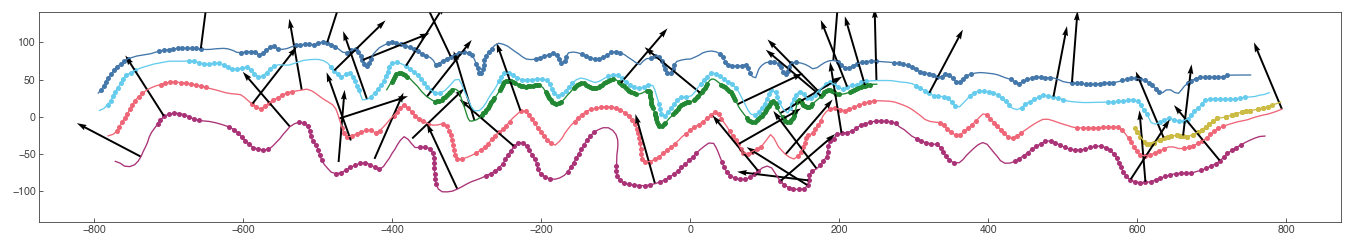

In [6]:
# Check: the observations on the section (not saved).
colors = {n: figstyle.HORIZON_PALETTE[i % len(figstyle.HORIZON_PALETTE)] for i, n in enumerate(horizon_names)}
pts = np.vstack(horizons_full)
zlim = (pts[:, 1].min() - 40, pts[:, 1].max() + 40)
fig, ax = plt.subplots(figsize=(14, 3.2))
for name, full, c in zip(horizon_names, horizons_full, horizons):
    ax.plot(full[:, 0], full[:, 1], color=colors[name], lw=0.8)
    ax.scatter(c[:, 0], c[:, 1], s=4, color=colors[name])
ax.quiver(gp[:, 0], gp[:, 1], gv[:, 0], gv[:, 1], color="k", width=0.0015)
ax.set_ylim(*zlim)
ax.set_aspect("equal")
plt.show()